In [28]:
from concurrent.futures import ThreadPoolExecutor

import geopandas as gpd
import numpy as np
import odc.geo
from odc.stac import load
from pystac_client import Client
from shapely import geometry
from sklearn.ensemble import RandomForestClassifier

%matplotlib inline

import datacube
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import sys, os
sys.path.insert(1, os.path.abspath('../Tools'))

from pystac.client import Client


import rasterio
import matplotlib
import pickle
import joblib
from utils import load_data, predict_xr

In [29]:
%reload_ext autoreload
%autoreload 2

## Find and load data

Load data and set up your array to use for prediction

In [39]:
# Configure some things up front
chunks = dict(x=2048, y=2048)
datetime = "2024"

bbox = [178.36683199429106, -17.706311982643278, 178.54589121502428, -17.561129121023423]
bbox_geometry = geometry.box(*bbox)

gdf = gpd.GeoDataFrame({'geometry': [bbox_geometry]}, crs='EPSG:4326')
gdf.explore()

In [40]:
catalog = "https://stac.digitalearthpacific.org"
client = Client.open(catalog)

year = '2024'
items = list(
    client.search(
        collections=["dep_s2_geomad"],
        bbox=bbox,
        datetime=year
    ).items()
)

In [41]:
print(f"Found {len(items)} items in for {datetime}")

Found 2 items in for 2024


In [42]:
bbox_bounds = [178.36574794372646, -17.706311982643278, 178.5471181218782, -17.561129121023423]

# Run the updated function
data = load_data(
    bbox=bbox_bounds,  
    year="2024"  # Pass the target year seamlessly
)


Successfully found and loading 2 tiles for the year 2024...
Searching for Sentinel-1 radar data...
Total S1 items returned for bbox: 16
Sample Item ID: dep_s1_geomad_064_021_2024
Sample Item Properties: {'created': '2025-11-06T23:58:05.769540Z', 'datetime': '2024-01-01T00:00:00Z', 'proj:bbox': [3144000.0, -1984000.0, 3240000.0, -1888000.0], 'proj:shape': [9600, 9600], 'end_datetime': '2024-12-31T23:59:59Z', 'proj:geometry': {'type': 'Polygon', 'coordinates': [[[3144000.0, -1984000.0], [3240000.0, -1984000.0], [3240000.0, -1888000.0], [3144000.0, -1888000.0], [3144000.0, -1984000.0]]]}, 'proj:transform': [10.0, 0.0, 3144000.0, 0.0, -10.0, -1888000.0, 0.0, 0.0, 1.0], 'start_datetime': '2024-01-01T00:00:00.000Z', 'proj:code': 'EPSG:3832'}
-> Successfully found and filtered 2 radar tiles for 2024...
Successfully merged Sentinel-1 data into master dataset.


In [43]:
data

<xarray.Dataset> Size: 443MB
Dimensions:        (y: 1687, x: 2020)
Coordinates:
  * y              (y) float64 13kB -1.973e+06 -1.973e+06 ... -1.99e+06
  * x              (x) float64 16kB 3.158e+06 3.158e+06 ... 3.178e+06 3.178e+06
    spatial_ref    int32 4B 3832
    time           datetime64[ns] 8B 2024-01-01
Data variables: (12/28)
    blue           (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    green          (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    red            (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge1       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge2       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge3       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    ...             ...
    elevation_std  (y, x) float32 14MB dask.array<chunksize=(1686, 2019), meta=np.ndarray>
    slope          (y, x) float32 14MB nan nan nan nan 14.04 ... nan nan nan nan
    aspect         (y, x) float32 14MB nan nan nan nan 211.5 ... nan nan nan nan
    mean_vv        (y, x) float32 14MB 0.1291 0.1264 0.1264 ... 0.2512 0.2322
    mean_vh        (y, x) float32 14MB 0.03405 0.03098 ... 0.05507 0.05002
    mean_vv_vh     (y, x) float32 14MB 3.791 4.08 4.08 ... 4.565 4.561 4.642

In [44]:
# import numpy as np
# import xarray as xr
# import rioxarray

# # --- 1. Reproject Elevation to Meters (Crucial for Accurate Terrain Math) ---
# print("Reprojecting elevation to metric system (EPSG:32760)...")
# elevation_metric = data["elevation"].rio.reproject("EPSG:32760", resolution=30)

# # --- 2. Calculate Terrain Gradients using Numpy ---
# transform = elevation_metric.rio.transform()
# dx = abs(transform[0])  # Pixel size along X-axis
# dy = abs(transform[4])  # Pixel size along Y-axis

# # Extract raw elevation array
# dem_array = elevation_metric.values

# # Calculate gradients along the Y (North-South) and X (East-West) axes
# dy_grad, dx_grad = np.gradient(dem_array, dy, dx)

# # --- 3. Compute Slope (Degrees) ---
# slope_radians = np.arctan(np.sqrt(dx_grad**2 + dy_grad**2))
# slope_degrees = np.degrees(slope_radians)

# # --- 4. Compute Aspect (Degrees from North) ---
# aspect_radians = np.arctan2(dy_grad, -dx_grad)
# aspect_degrees = np.degrees(aspect_radians)
# aspect_degrees = (270.0 - aspect_degrees) % 360.0

# # --- 5. Convert back to Xarray and Match Your Original Grid ---
# slope_xr = xr.DataArray(
#     slope_degrees, 
#     coords=elevation_metric.coords, 
#     dims=elevation_metric.dims
# ).rio.write_crs("EPSG:32760")

# aspect_xr = xr.DataArray(
#     aspect_degrees, 
#     coords=elevation_metric.coords, 
#     dims=elevation_metric.dims
# ).rio.write_crs("EPSG:32760")

# # Reproject them back to your original dataset coordinate system (EPSG:4326)
# print("Stacking terrain variables back into master data array...")

# # Extract explicit grid parameters to ensure a perfect structural match
# target_crs = data["elevation"].rio.crs
# target_shape = (data["elevation"].shape[-2], data["elevation"].shape[-1])
# target_transform = data["elevation"].rio.transform()

# # Universally supported reproject call
# data["slope"] = slope_xr.rio.reproject(
#     dst_crs=target_crs,
#     shape=target_shape,
#     transform=target_transform
# )

# data["aspect"] = aspect_xr.rio.reproject(
#     dst_crs=target_crs,
#     shape=target_shape,
#     transform=target_transform
# )

# print("Success! 'slope' and 'aspect' features have been successfully added.")


In [45]:
data

<xarray.Dataset> Size: 443MB
Dimensions:        (y: 1687, x: 2020)
Coordinates:
  * y              (y) float64 13kB -1.973e+06 -1.973e+06 ... -1.99e+06
  * x              (x) float64 16kB 3.158e+06 3.158e+06 ... 3.178e+06 3.178e+06
    spatial_ref    int32 4B 3832
    time           datetime64[ns] 8B 2024-01-01
Data variables: (12/28)
    blue           (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    green          (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    red            (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge1       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge2       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    rededge3       (y, x) uint16 7MB dask.array<chunksize=(1687, 2020), meta=np.ndarray>
    ...             ...
    elevation_std  (y, x) float32 14MB dask.array<chunksize=(1686, 2019), meta=np.ndarray>
    slope          (y, x) float32 14MB nan nan nan nan 14.04 ... nan nan nan nan
    aspect         (y, x) float32 14MB nan nan nan nan 211.5 ... nan nan nan nan
    mean_vv        (y, x) float32 14MB 0.1291 0.1264 0.1264 ... 0.2512 0.2322
    mean_vh        (y, x) float32 14MB 0.03405 0.03098 ... 0.05507 0.05002
    mean_vv_vh     (y, x) float32 14MB 3.791 4.08 4.08 ... 4.565 4.561 4.642

In [46]:
loaded_model = joblib.load("test_model.dump")

In [47]:
loaded_data = data.compute()

## Run ML classifier

In [48]:
filled = loaded_data.fillna(-9999.0)

In [49]:
# This runs the actual prediction
predicted = predict_xr(loaded_model, filled, proba=True)

# Convert to int
cleaned_predictions = predicted.copy(deep=True)
cleaned_predictions.predictions.data = predicted.predictions.data.astype(np.int8)
cleaned_predictions.probabilities.data = predicted.probabilities.data.astype(np.float32)

cleaned_predictions = cleaned_predictions.rename({"predictions": "lulc", "probabilities": "prob"})

predicting...
   probabilities...


In [50]:
cleaned_predictions

<xarray.Dataset> Size: 17MB
Dimensions:      (x: 2020, y: 1687)
Coordinates:
  * x            (x) float64 16kB 3.158e+06 3.158e+06 ... 3.178e+06 3.178e+06
  * y            (y) float64 13kB -1.973e+06 -1.973e+06 ... -1.99e+06 -1.99e+06
    spatial_ref  int32 4B 0
Data variables:
    lulc         (y, x) int8 3MB 2 2 2 2 2 2 2 2 2 2 2 ... 2 2 2 2 2 2 2 2 2 2 2
    prob         (y, x) float32 14MB 46.2 46.2 46.2 46.2 ... 46.2 46.2 46.2 46.2
Attributes:
    grid_mapping:  spatial_ref

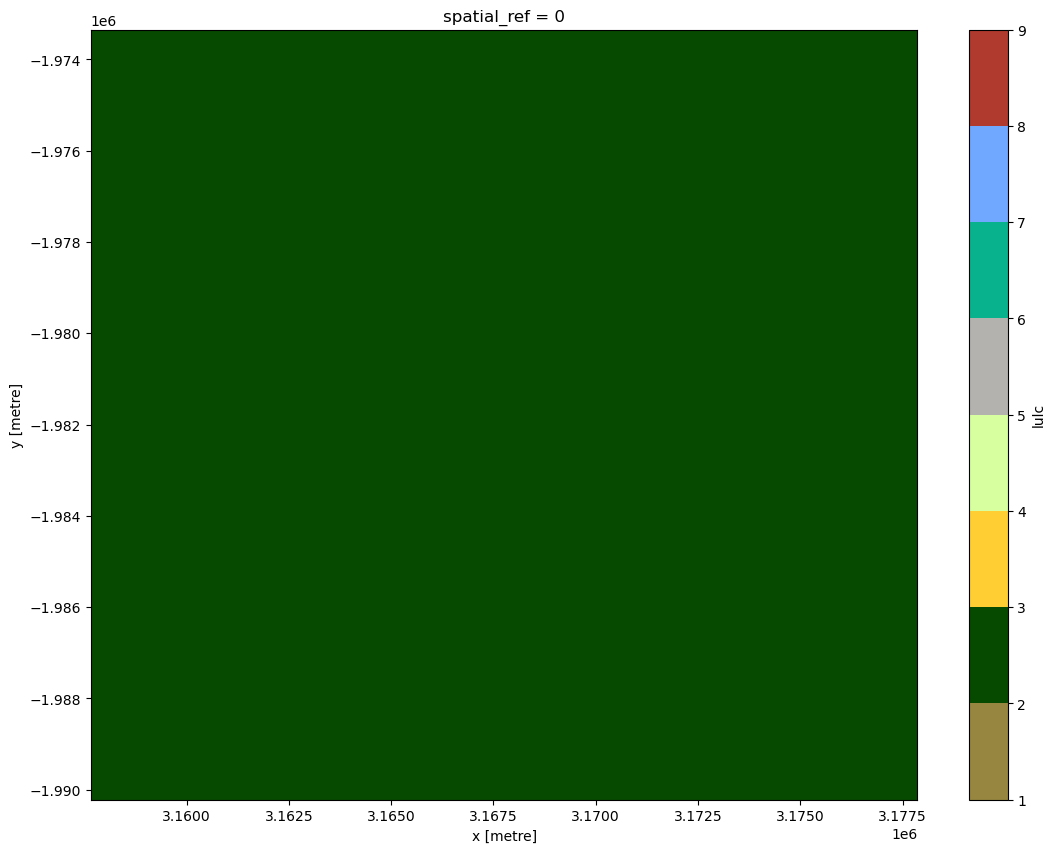

In [51]:
from matplotlib import colors

classes = [
    [1, "bare_land", "#968640"],
    [2, "forest", "#064a00"],
    [3, "crops", "#ffce33"],
    [4, "grassland", "#d7ffa0"],
    [5, "settlements", "#b3b2ae"],
    [6, "mangroves", "#07b28d"],
    [7, "water", "#71a8ff"],
    [8, "quarry", "#b03a2e"]
]

values_list = [c[0] for c in classes]
color_list = [c[2] for c in classes]

# Build a listed colormap.
c_map = colors.ListedColormap(color_list)
bounds = values_list + [9]
norm = colors.BoundaryNorm(bounds, c_map.N)

cleaned_predictions.lulc.plot.imshow(cmap=c_map, norm=norm, size=10)

In [52]:
# Write GeoTIFF
cleaned_predictions.lulc.odc.write_cog("lulc_2022.tif", overwrite=True)

PosixPath('lulc_2022.tif')